## 2.1 Feature preparation

For this task you need the task 1 features csv(task1_final_features.csv)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

# CSV exported from Task 1
features = pd.read_csv('task1_final_features.csv')
print(features.columns.tolist())
features.head()

['Ticker', 'Mean_Weekly_Return', 'Weekly_Beta', 'Aligned_Weekly_Observations', 'Recency', 'Frequency', 'Monetary']


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations,Recency,Frequency,Monetary
0,A,0.001121,1.074723,207,11,2,1.400180e+10
1,AAPL,0.003930,1.174836,207,11,2,6.233034e+11
2,ABBV,0.003749,0.425366,207,11,3,6.837054e+10
3,ABNB,0.001475,1.472709,207,11,3,3.652850e+10
4,ABT,0.000971,0.583543,207,11,1,3.523027e+10


In [4]:
# Read the final feature table created in Task 1
stocks = features[['Ticker', 'Mean_Weekly_Return', 'Weekly_Beta',
                   'Recency', 'Frequency', 'Monetary']].copy()
stocks = stocks.drop_duplicates('Ticker').set_index('Ticker')
stocks = stocks.replace([np.inf, -np.inf], np.nan).dropna()
stocks = stocks[(stocks['Recency'] >= 0) &
                (stocks['Frequency'] >= 0) &
                (stocks['Monetary'] >= 0)]

stocks['Log_Monetary'] = np.log1p(stocks['Monetary'])
risk = stocks[['Mean_Weekly_Return', 'Weekly_Beta']].copy()
rfm = stocks[['Recency', 'Frequency', 'Log_Monetary']].copy()

print('Shares used in both analyses:', len(stocks))
if len(stocks) < 4:
    raise ValueError('At least 4 valid shares are needed for cluster comparison')

print('Skewness:')
display(stocks[risk.columns.tolist() + ['Recency', 'Frequency', 'Monetary', 'Log_Monetary']].skew().round(2))

print('Possible outliers (1.5 x IQR):')
for col in list(risk.columns) + list(rfm.columns):
    q1, q3 = stocks[col].quantile([0.25, 0.75])
    count = ((stocks[col] < q1 - 1.5 * (q3 - q1)) |
             (stocks[col] > q3 + 1.5 * (q3 - q1))).sum()
    print(col, count)


Shares used in both analyses: 498
Skewness:


,0
Mean_Weekly_Return,3.56
Weekly_Beta,1.25
Recency,3.61
Frequency,0.41
Monetary,11.74
Log_Monetary,1.05


Possible outliers (1.5 x IQR):
Mean_Weekly_Return 19
Weekly_Beta 12
Recency 97
Frequency 2
Log_Monetary 13


Monetary is transformed using log1p because it is usually strongly right-skewed. Other features are kept unchanged, and possible outliers are shown rather than removed automatically. Both clustering analyses use the same shares.

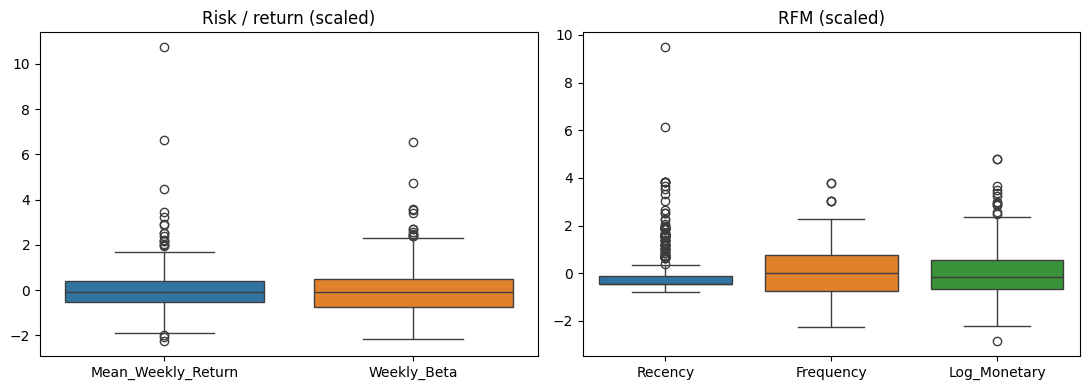

In [5]:
risk_scaled = pd.DataFrame(StandardScaler().fit_transform(risk), index=risk.index, columns=risk.columns)
rfm_scaled = pd.DataFrame(StandardScaler().fit_transform(rfm), index=rfm.index, columns=rfm.columns)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=risk_scaled, ax=axes[0]); axes[0].set_title('Risk / return (scaled)')
sns.boxplot(data=rfm_scaled, ax=axes[1]); axes[1].set_title('RFM (scaled)')
plt.tight_layout(); plt.show()

## 2.2 Agglomerative clustering (Ward)

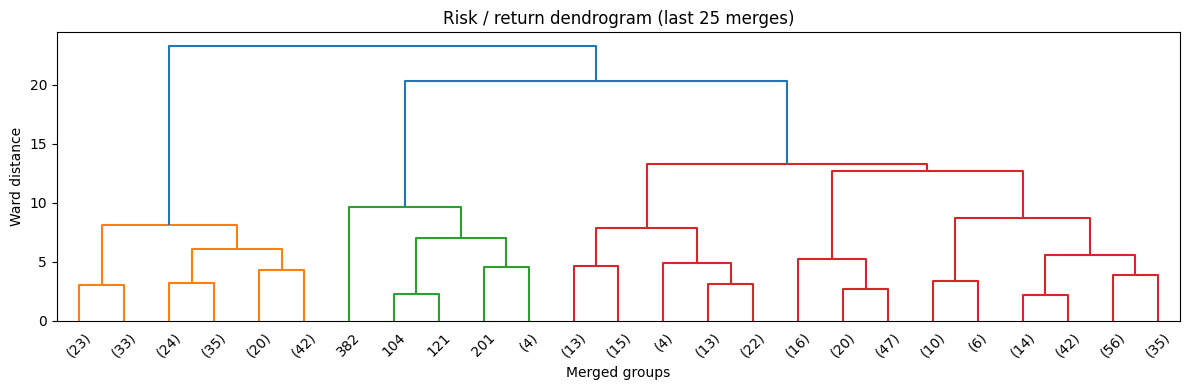

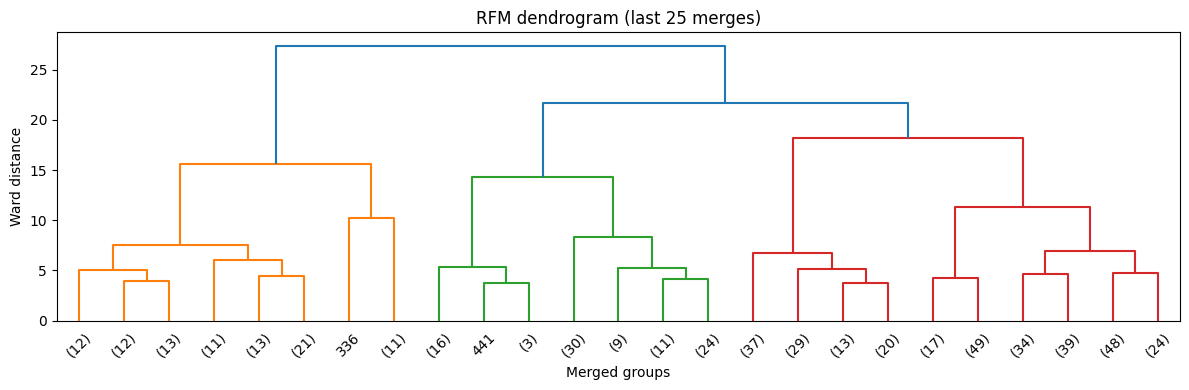

In [6]:
for name, X in [('Risk / return', risk_scaled), ('RFM', rfm_scaled)]:
    Z = linkage(X, method='ward', metric='euclidean')
    plt.figure(figsize=(12, 4))
    dendrogram(Z, truncate_mode='lastp', p=25, show_leaf_counts=True)
    plt.title(name + ' dendrogram (last 25 merges)')
    plt.xlabel('Merged groups'); plt.ylabel('Ward distance')
    plt.tight_layout(); plt.show()

In [7]:
def ward_scores(X):
    rows = []
    for k in range(2, min(8, len(X)-1) + 1):
        labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
        rows.append({'k': k, 'silhouette': silhouette_score(X, labels),
                     'cluster_sizes': dict(pd.Series(labels).value_counts().sort_index())})
    return pd.DataFrame(rows)

ward_risk_scores = ward_scores(risk_scaled)
ward_rfm_scores = ward_scores(rfm_scaled)
print('Risk / return:'); display(ward_risk_scores)
print('RFM:'); display(ward_rfm_scores)

Risk / return:


,k,silhouette,cluster_sizes
0,2,0.288845,"{0: 321, 1: 177}"
1,3,0.320715,"{0: 313, 1: 177, 2: 8}"
2,4,0.297311,"{0: 246, 1: 177, 2: 8, 3: 67}"
3,5,0.288463,"{0: 8, 1: 177, 2: 163, 3: 67, 4: 83}"
4,6,0.289506,"{0: 163, 1: 177, 2: 7, 3: 67, 4: 83, 5: 1}"
5,7,0.296698,"{0: 177, 1: 67, 2: 7, 3: 147, 4: 83, 5: 1, 6: 16}"
6,8,0.279156,"{0: 67, 1: 121, 2: 7, 3: 147, 4: 83, 5: 1, 6: ..."


RFM:


,k,silhouette,cluster_sizes
0,2,0.358679,"{0: 404, 1: 94}"
1,3,0.316000,"{0: 310, 1: 94, 2: 94}"
2,4,0.287608,"{0: 94, 1: 211, 2: 94, 3: 99}"
3,5,0.310284,"{0: 94, 1: 211, 2: 12, 3: 99, 4: 82}"
4,6,0.318334,"{0: 211, 1: 74, 2: 12, 3: 99, 4: 82, 5: 20}"
5,7,0.306113,"{0: 12, 1: 74, 2: 145, 3: 99, 4: 82, 5: 20, 6:..."
6,8,0.307970,"{0: 74, 1: 82, 2: 145, 3: 99, 4: 11, 5: 20, 6:..."


In [8]:
# Starting point: highest silhouette. Check sizes and profiles before finalising k.
k_ward_risk = int(ward_risk_scores.loc[ward_risk_scores.silhouette.idxmax(), 'k'])
k_ward_rfm = int(ward_rfm_scores.loc[ward_rfm_scores.silhouette.idxmax(), 'k'])

stocks['Ward_Risk'] = AgglomerativeClustering(n_clusters=k_ward_risk, linkage='ward').fit_predict(risk_scaled)
stocks['Ward_RFM'] = AgglomerativeClustering(n_clusters=k_ward_rfm, linkage='ward').fit_predict(rfm_scaled)
print('Chosen Ward k:', k_ward_risk, '(risk),', k_ward_rfm, '(RFM)')
display(stocks.groupby('Ward_Risk')[['Mean_Weekly_Return', 'Weekly_Beta']].agg(['mean', 'count']).round(4))
display(stocks.groupby('Ward_RFM')[['Recency', 'Frequency', 'Monetary']].agg(['mean', 'count']).round(2))

Chosen Ward k: 3 (risk), 2 (RFM)


Mean_Weekly_Return       Weekly_Beta      
                        mean count        mean count
Ward_Risk                                           
0                     0.0032   313      1.1780   313
1                     0.0021   177      0.5789   177
2                     0.0174     8      2.3692     8

Recency       Frequency            Monetary      
            mean count      mean count          mean count
Ward_RFM                                                  
0          12.36   404      3.22   404  3.820898e+10   404
1          55.53    94      2.07    94  4.565006e+10    94

## 2.3 K-Means clustering

In [9]:
def kmeans_scores(X):
    rows = []
    for k in range(2, min(8, len(X)-1) + 1):
        model = KMeans(n_clusters=k, random_state=42, n_init=20)
        labels = model.fit_predict(X)
        rows.append({'k': k, 'silhouette': silhouette_score(X, labels),
                     'inertia': model.inertia_,
                     'cluster_sizes': dict(pd.Series(labels).value_counts().sort_index())})
    return pd.DataFrame(rows)

km_risk_scores = kmeans_scores(risk_scaled)
km_rfm_scores = kmeans_scores(rfm_scaled)
print('Risk / return:'); display(km_risk_scores)
print('RFM:'); display(km_rfm_scores)

Risk / return:


,k,silhouette,inertia,cluster_sizes
0,2,0.399825,659.460929,"{0: 351, 1: 147}"
1,3,0.349059,498.106754,"{0: 281, 1: 208, 2: 9}"
2,4,0.336474,386.990707,"{0: 179, 1: 121, 2: 8, 3: 190}"
3,5,0.330505,318.800405,"{0: 167, 1: 130, 2: 43, 3: 2, 4: 156}"
4,6,0.349941,272.212741,"{0: 142, 1: 187, 2: 8, 3: 57, 4: 1, 5: 103}"
5,7,0.336159,225.382031,"{0: 110, 1: 42, 2: 57, 3: 148, 4: 2, 5: 7, 6: ..."
6,8,0.330770,195.402596,"{0: 132, 1: 104, 2: 72, 3: 2, 4: 51, 5: 94, 6:..."


RFM:


,k,silhouette,inertia,cluster_sizes
0,2,0.418999,1094.049704,"{0: 72, 1: 426}"
1,3,0.324539,818.237455,"{0: 276, 1: 65, 2: 157}"
2,4,0.340100,625.239576,"{0: 123, 1: 98, 2: 216, 3: 61}"
3,5,0.356812,528.698704,"{0: 202, 1: 11, 2: 70, 3: 124, 4: 91}"
4,6,0.346771,447.487971,"{0: 107, 1: 11, 2: 72, 3: 120, 4: 44, 5: 144}"
5,7,0.348644,396.278791,"{0: 120, 1: 44, 2: 11, 3: 144, 4: 107, 5: 1, 6..."
6,8,0.347018,354.681706,"{0: 68, 1: 108, 2: 14, 3: 19, 4: 63, 5: 142, 6..."


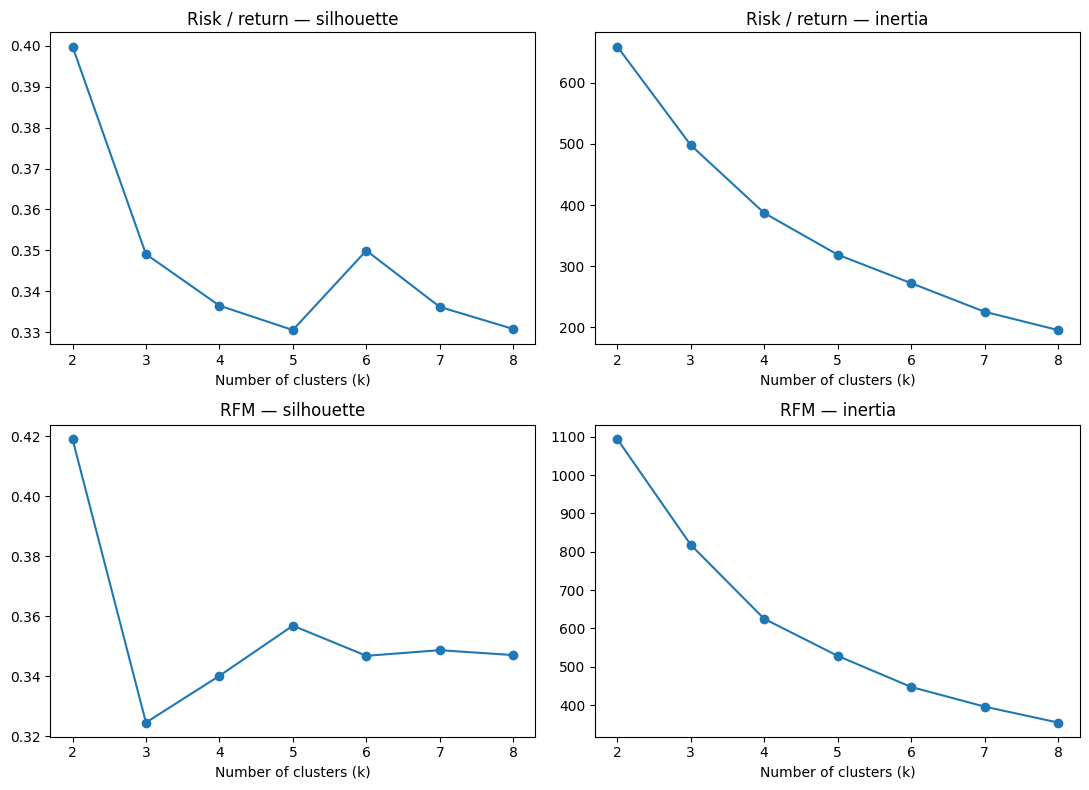

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, (name, scores) in enumerate([('Risk / return', km_risk_scores), ('RFM', km_rfm_scores)]):
    axes[row, 0].plot(scores['k'], scores['silhouette'], marker='o')
    axes[row, 0].set_title(name + ' — silhouette')
    axes[row, 1].plot(scores['k'], scores['inertia'], marker='o')
    axes[row, 1].set_title(name + ' — inertia')
    for ax in axes[row]: ax.set_xlabel('Number of clusters (k)')
plt.tight_layout(); plt.show()

In [11]:
k_km_risk = int(km_risk_scores.loc[km_risk_scores.silhouette.idxmax(), 'k'])
k_km_rfm = int(km_rfm_scores.loc[km_rfm_scores.silhouette.idxmax(), 'k'])

stocks['KMeans_Risk'] = KMeans(n_clusters=k_km_risk, random_state=42, n_init=20).fit_predict(risk_scaled)
stocks['KMeans_RFM'] = KMeans(n_clusters=k_km_rfm, random_state=42, n_init=20).fit_predict(rfm_scaled)
print('Chosen K-Means k:', k_km_risk, '(risk),', k_km_rfm, '(RFM)')

Chosen K-Means k: 2 (risk), 2 (RFM)


## 2.4 Cluster profiles and algorithm comparison

In [12]:
for group, cols in [('Risk', ['Mean_Weekly_Return', 'Weekly_Beta']), ('RFM', ['Recency', 'Frequency', 'Monetary'])]:
    for algorithm in ['Ward', 'KMeans']:
        cluster_col = algorithm + '_' + group
        print('\n', cluster_col)
        profile = stocks.groupby(cluster_col)[cols].mean().round(4)
        profile.insert(0, 'Shares', stocks.groupby(cluster_col).size())
        display(profile)


 Ward_Risk


,Shares,Mean_Weekly_Return,Weekly_Beta
Ward_Risk,,,
0,313,0.0032,1.1780
1,177,0.0021,0.5789
2,8,0.0174,2.3692



 KMeans_Risk


,Shares,Mean_Weekly_Return,Weekly_Beta
KMeans_Risk,,,
0,351,0.0020,0.7986
1,147,0.0054,1.4274



 Ward_RFM


,Shares,Recency,Frequency,Monetary
Ward_RFM,,,,
0,404,12.3614,3.2203,3.820898e+10
1,94,55.5319,2.0745,4.565006e+10



 KMeans_RFM


,Shares,Recency,Frequency,Monetary
KMeans_RFM,,,,
0,72,62.4861,1.8472,8.060058e+10
1,426,13.4155,3.1995,3.268613e+10


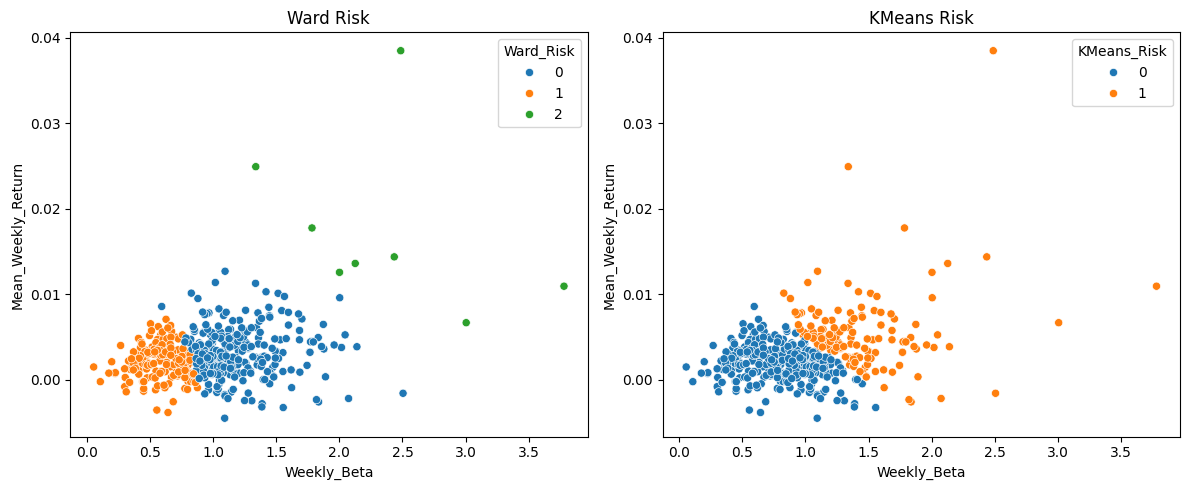

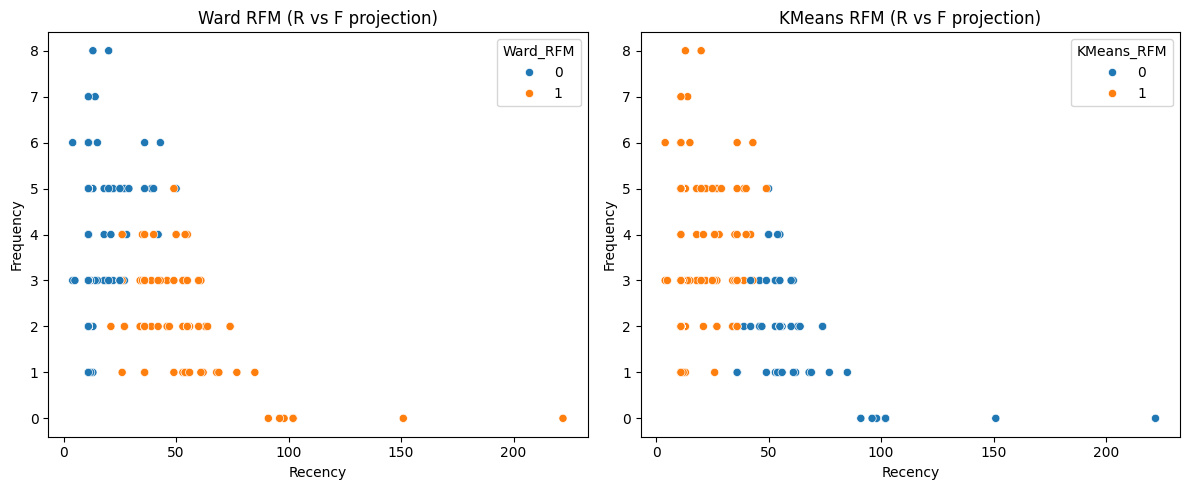

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label in zip(axes, ['Ward_Risk', 'KMeans_Risk']):
    sns.scatterplot(data=stocks, x='Weekly_Beta', y='Mean_Weekly_Return', hue=label,
                    palette='tab10', ax=ax, s=35)
    ax.set_title(label.replace('_', ' '))
plt.tight_layout(); plt.show()

# RFM has 3 dimensions; this plot displays R and F only, with Monetary omitted from the axes.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label in zip(axes, ['Ward_RFM', 'KMeans_RFM']):
    sns.scatterplot(data=stocks, x='Recency', y='Frequency', hue=label, palette='tab10', ax=ax, s=35)
    ax.set_title(label.replace('_', ' ') + ' (R vs F projection)')
plt.tight_layout(); plt.show()

In [14]:
print('Ward vs K-Means — Risk adjusted Rand index:',
      round(adjusted_rand_score(stocks['Ward_Risk'], stocks['KMeans_Risk']), 3))
print('Ward vs K-Means — RFM adjusted Rand index:',
      round(adjusted_rand_score(stocks['Ward_RFM'], stocks['KMeans_RFM']), 3))

print('Risk membership comparison:')
display(pd.crosstab(stocks['Ward_Risk'], stocks['KMeans_Risk']))
print('RFM membership comparison:')
display(pd.crosstab(stocks['Ward_RFM'], stocks['KMeans_RFM']))

Ward vs K-Means — Risk adjusted Rand index: 0.087
Ward vs K-Means — RFM adjusted Rand index: 0.754
Risk membership comparison:


KMeans_Risk,0,1
Ward_Risk,,
0,174,139
1,177,0
2,0,8


RFM membership comparison:


KMeans_RFM,0,1
Ward_RFM,,
0,2,402
1,70,24


## 2.5 RFM sensitivity and correlated inputs

,Recency,Frequency,Log_Monetary
Recency,1.000,-0.340,0.165
Frequency,-0.340,1.000,0.022
Log_Monetary,0.165,0.022,1.000


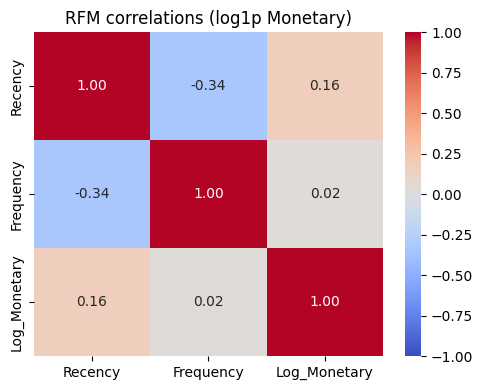

In [15]:
correlations = stocks[['Recency', 'Frequency', 'Log_Monetary']].corr()
display(correlations.round(3))
plt.figure(figsize=(5, 4))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('RFM correlations (log1p Monetary)')
plt.tight_layout(); plt.show()

In [16]:
# Repeat Ward using R and F, with the same shares and the same k
rf_scaled = StandardScaler().fit_transform(stocks[['Recency', 'Frequency']])
stocks['Ward_RF'] = AgglomerativeClustering(n_clusters=k_ward_rfm, linkage='ward').fit_predict(rf_scaled)

ari = adjusted_rand_score(stocks['Ward_RFM'], stocks['Ward_RF'])
print('Adjusted Rand index (RFM vs RF):', round(ari, 3))
print('Membership comparison:')
display(pd.crosstab(stocks['Ward_RFM'], stocks['Ward_RF']))

print('Mean traded value (USD) with Monetary:')
display(stocks.groupby('Ward_RFM')['Monetary'].agg(['count', 'mean', 'median']).round(2))
print('Mean traded value (USD) without Monetary:')
display(stocks.groupby('Ward_RF')['Monetary'].agg(['count', 'mean', 'median']).round(2))

Adjusted Rand index (RFM vs RF): 0.953
Membership comparison:


Ward_RF,0,1
Ward_RFM,,
0,402,2
1,3,91


Mean traded value (USD) with Monetary:


,count,mean,median
Ward_RFM,,,
0,404,3.820898e+10,1.547309e+10
1,94,4.565006e+10,2.095020e+10


Mean traded value (USD) without Monetary:


,count,mean,median
Ward_RF,,,
0,405,3.768854e+10,1.545679e+10
1,93,4.799647e+10,2.105259e+10


## Save results

In [17]:
import os
os.makedirs('sp500_data', exist_ok=True)
stocks.reset_index().to_csv('sp500_data/task2_cluster_assignments.csv', index=False)
ward_risk_scores.to_csv('sp500_data/ward_risk_scores.csv', index=False)
ward_rfm_scores.to_csv('sp500_data/ward_rfm_scores.csv', index=False)
km_risk_scores.to_csv('sp500_data/kmeans_risk_scores.csv', index=False)
km_rfm_scores.to_csv('sp500_data/kmeans_rfm_scores.csv', index=False)
print('Task 2 results saved in sp500_data/')

Task 2 results saved in sp500_data/
